# 00 — Data audit

Structural checks of every flow file and road network; demand plots for the Jinan training flow only.

In [1]:
import json
from collections import Counter
from collections.abc import Sequence
from numbers import Real

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from trafficrl.data.roadnet import (
    DIRECTIONS, MOVEMENT_KINDS, N_APPROACHES, YELLOW_PHASE, Roadnet, load_roadnet,
)
from trafficrl.data.splits import REPO_ROOT, load_splits, verify_hashes
from trafficrl.utils.config import load_config
from trafficrl.utils.plotting import BLUE, INK_SECONDARY, ORANGE, apply_style, save_figure

cfg = load_config(REPO_ROOT / "configs" / "eda.yaml")
EPISODE = cfg["sim"]["episode_seconds"]
BIN = cfg["eda"]["arrival_bin_seconds"]
DOCS = REPO_ROOT / "docs"
FIG_DIR = DOCS / "figures" / "audit"
apply_style()

### Helpers

In [2]:
FLOW_KEYS = ("vehicle", "route", "interval", "startTime", "endTime")
VEHICLE_KEYS = ("length", "width", "maxPosAcc", "maxNegAcc", "usualPosAcc", "usualNegAcc",
                "minGap", "maxSpeed", "headwayTime")
YELLOW_SECONDS = 5
N_PHASES = 9

FLOW_DEFECTS = (
    "missing_field", "missing_vehicle_field", "wrong_type", "duplicate_records",
    "start_time_out_of_range", "start_time_not_integer", "end_before_start",
    "multi_vehicle_records", "route_too_short", "unknown_road", "disconnected_route",
    "route_not_from_boundary", "route_repeats_road", "nonpositive_vehicle_value",
    "speed_above_lane_limit", "unexpected_field", "unexpected_string_value",
)
FLOW_INFO = (
    "records", "arrival_burst_bins", "arrival_low_bins", "same_second_same_entry_lane",
    "route_ends_inside_network", "route_revisits_intersection", "vehicle_profiles",
)
ROADNET_DEFECTS = (
    "intersection_without_4_in_roads", "intersection_without_4_out_roads",
    "intersection_without_12_movements", "intersection_without_9_phases",
    "transition_phase_not_5s", "invalid_phase_movement_index", "unknown_movement_type",
    "lane_link_index_out_of_range", "road_with_unknown_intersection",
    "movement_with_unknown_road", "nonpositive_road_length", "nonpositive_lane_value",
)
ROADNET_INFO = ("intersections_signalised", "intersections_virtual", "roads", "lanes")


def is_number(x: object) -> bool:
    return isinstance(x, Real) and not isinstance(x, bool)


def arrival_counts(flows: Sequence[dict], episode_seconds: int, bin_seconds: int) -> np.ndarray:
    """Vehicles entering the network per ``bin_seconds`` window."""
    n_bins = -(-episode_seconds // bin_seconds)
    counts = np.zeros(n_bins, dtype=int)
    for v in flows:
        t = v.get("startTime")
        if is_number(t) and 0 <= t < episode_seconds:
            counts[int(t) // bin_seconds] += 1
    return counts


def burst_threshold(counts: np.ndarray) -> float:
    """Upper fence Q3 + 1.5·IQR."""
    q1, q3 = np.percentile(counts, [25, 75])
    return float(q3 + 1.5 * (q3 - q1))


def low_threshold(counts: np.ndarray) -> float:
    """Lower fence Q1 − 1.5·IQR."""
    q1, q3 = np.percentile(counts, [25, 75])
    return float(q1 - 1.5 * (q3 - q1))


def audit_flow(flows: Sequence[dict], roadnet: Roadnet, episode_seconds: int,
               bin_seconds: int = 60) -> dict[str, int]:
    """Count structural problems in one flow file."""
    c: Counter[str] = Counter({k: 0 for k in FLOW_DEFECTS + FLOW_INFO})
    c["records"] = len(flows)
    road_ids = roadnet.road_ids
    max_lane_speed = max(roadnet.lane_max_speed.values())
    seen: set[str] = set()
    entry: Counter[tuple] = Counter()
    profiles: set[str] = set()

    for v in flows:
        key = json.dumps(v, sort_keys=True)
        c["duplicate_records"] += key in seen
        seen.add(key)

        c["missing_field"] += sum(k not in v or v[k] is None for k in FLOW_KEYS)
        c["unexpected_field"] += sum(k not in FLOW_KEYS for k in v)

        veh = v.get("vehicle")
        if isinstance(veh, dict):
            profiles.add(json.dumps(veh, sort_keys=True))
            c["missing_vehicle_field"] += sum(k not in veh or veh[k] is None for k in VEHICLE_KEYS)
            c["unexpected_field"] += sum(k not in VEHICLE_KEYS for k in veh)
            for k in VEHICLE_KEYS:
                x = veh.get(k)
                if x is None:
                    continue
                if not is_number(x):
                    c["wrong_type"] += 1
                    c["unexpected_string_value"] += isinstance(x, str)
                elif x <= 0:
                    c["nonpositive_vehicle_value"] += 1
            speed = veh.get("maxSpeed")
            c["speed_above_lane_limit"] += is_number(speed) and speed > max_lane_speed + 1e-9
        elif veh is not None:
            c["wrong_type"] += 1

        start, end = v.get("startTime"), v.get("endTime")
        for t in (start, end, v.get("interval")):
            if t is not None and not is_number(t):
                c["wrong_type"] += 1
                c["unexpected_string_value"] += isinstance(t, str)
        if is_number(start):
            c["start_time_out_of_range"] += not 0 <= start < episode_seconds
            c["start_time_not_integer"] += start != int(start)
            if is_number(end):
                c["end_before_start"] += end < start
                c["multi_vehicle_records"] += end > start

        route = v.get("route")
        if route is None:
            continue
        if not isinstance(route, list) or not all(isinstance(r, str) for r in route):
            c["wrong_type"] += 1
            continue
        c["route_too_short"] += len(route) < 2
        unknown = [r for r in route if r not in road_ids]
        c["unknown_road"] += len(unknown)
        c["route_repeats_road"] += len(set(route)) != len(route)
        if unknown or not route:
            continue
        c["disconnected_route"] += any(
            (a, b) not in roadnet.road_links for a, b in zip(route, route[1:], strict=False)
        )
        c["route_not_from_boundary"] += roadnet.road_start[route[0]] not in roadnet.virtual_ids
        c["route_ends_inside_network"] += roadnet.road_end[route[-1]] not in roadnet.virtual_ids
        nodes = [roadnet.road_end[r] for r in route[:-1]]
        c["route_revisits_intersection"] += len(set(nodes)) != len(nodes)
        if is_number(start) and len(route) >= 2:
            entry[(start, route[0], route[1])] += 1

    counts = arrival_counts(flows, episode_seconds, bin_seconds)
    c["arrival_burst_bins"] = int((counts > burst_threshold(counts)).sum())
    c["arrival_low_bins"] = int((counts < low_threshold(counts)).sum())
    c["same_second_same_entry_lane"] = sum(n - 1 for n in entry.values() if n > 1)
    c["vehicle_profiles"] = len(profiles)
    return {k: int(c[k]) for k in FLOW_DEFECTS + FLOW_INFO}


def audit_roadnet(raw: dict) -> dict[str, int]:
    """Count structural problems in a road network."""
    c: Counter[str] = Counter({k: 0 for k in ROADNET_DEFECTS + ROADNET_INFO})
    inters = {i["id"]: i for i in raw["intersections"]}
    roads = {r["id"]: r for r in raw["roads"]}
    c["roads"] = len(roads)
    c["lanes"] = sum(len(r["lanes"]) for r in roads.values())

    for r in roads.values():
        ends = (r["startIntersection"], r["endIntersection"])
        c["road_with_unknown_intersection"] += any(e not in inters for e in ends)
        p = r["points"]
        c["nonpositive_road_length"] += (p[0]["x"], p[0]["y"]) == (p[-1]["x"], p[-1]["y"])
        c["nonpositive_lane_value"] += sum(
            ln["width"] <= 0 or ln["maxSpeed"] <= 0 for ln in r["lanes"]
        )

    for i in inters.values():
        if i["virtual"]:
            c["intersections_virtual"] += 1
            continue
        c["intersections_signalised"] += 1
        known = [r for r in i["roads"] if r in roads]
        n_in = sum(roads[r]["endIntersection"] == i["id"] for r in known)
        n_out = sum(roads[r]["startIntersection"] == i["id"] for r in known)
        c["intersection_without_4_in_roads"] += n_in != N_APPROACHES
        c["intersection_without_4_out_roads"] += n_out != N_APPROACHES
        links = i["roadLinks"]
        c["intersection_without_12_movements"] += len(links) != 3 * N_APPROACHES
        for link in links:
            c["unknown_movement_type"] += link["type"] not in MOVEMENT_KINDS
            ok = link["startRoad"] in roads and link["endRoad"] in roads
            c["movement_with_unknown_road"] += not ok
            if ok:
                n_start = len(roads[link["startRoad"]]["lanes"])
                n_end = len(roads[link["endRoad"]]["lanes"])
                c["lane_link_index_out_of_range"] += sum(
                    not (0 <= ll["startLaneIndex"] < n_start and 0 <= ll["endLaneIndex"] < n_end)
                    for ll in link["laneLinks"]
                )
        phases = i["trafficLight"]["lightphases"]
        c["intersection_without_9_phases"] += len(phases) != N_PHASES
        if phases:
            c["transition_phase_not_5s"] += phases[YELLOW_PHASE]["time"] != YELLOW_SECONDS
        c["invalid_phase_movement_index"] += sum(
            not 0 <= m < len(links) for p in phases for m in p["availableRoadLinks"]
        )
    return {k: int(c[k]) for k in ROADNET_DEFECTS + ROADNET_INFO}


def defects(counts: dict[str, int]) -> dict[str, int]:
    """Non-zero defect counts (empty = clean)."""
    keys = set(FLOW_DEFECTS) | set(ROADNET_DEFECTS)
    return {k: v for k, v in counts.items() if k in keys and v}


def entry_demand(flows: Sequence[dict]) -> pd.Series:
    """Vehicles per entry road, sorted descending."""
    s = pd.Series(Counter(v["route"][0] for v in flows), name="vehicles")
    return s.sort_values(ascending=False)


def movement_demand(flows: Sequence[dict], roadnet: Roadnet) -> pd.DataFrame:
    """Vehicles per movement at every signalised intersection."""
    used: Counter[tuple[str, str]] = Counter()
    for v in flows:
        route = v["route"]
        used.update(zip(route, route[1:], strict=False))
    rows = []
    for inter in roadnet.intersections.values():
        for m in inter.movements:
            rows.append({
                "intersection": inter.id,
                "approach": DIRECTIONS[inter.in_roads.index(m.start_road)],
                "kind": m.kind,
                "start_road": m.start_road,
                "end_road": m.end_road,
                "vehicles": used[(m.start_road, m.end_road)],
            })
    return pd.DataFrame(rows)

## 1. Defect counts on every file

In [3]:
splits = load_splits()
verify_hashes(splits)
res = {"episode_seconds": EPISODE, "arrival_bin_seconds": BIN, "datasets": {}}
for name, ds in splits.items():
    rn_path = ds["roadnet"].path
    roadnet = load_roadnet(rn_path)
    flows_out = {}
    for split, files in ds["splits"].items():
        for f in files:
            flows = json.loads(f.path.read_text())
            flows_out[f.path.name] = {"split": split, **audit_flow(flows, roadnet, EPISODE, BIN)}
    res["datasets"][name] = {
        "role": ds["role"],
        "roadnet": {"file": rn_path.name, **audit_roadnet(json.loads(rn_path.read_text()))},
        "flows": flows_out,
    }

flow_table = pd.DataFrame({
    f"{name} {f['split']} {fn.split('_', 3)[-1].removesuffix('.json')}": f
    for name, ds in res["datasets"].items() for fn, f in ds["flows"].items()
})
road_table = pd.DataFrame({name: ds["roadnet"] for name, ds in res["datasets"].items()})

n_bad = sum(sum(defects(f).values()) for ds in res["datasets"].values()
            for f in [ds["roadnet"], *ds["flows"].values()])
print("defects:", n_bad)
assert n_bad == 0
flow_table.loc[list(FLOW_DEFECTS)]

defects: 0


,jinan train jinan_real,jinan val jinan_real_2000,jinan test jinan_real_2500,hangzhou heldout hangzhou_real,hangzhou heldout hangzhou_real_5734,hangzhou heldout hangzhou_real_5816
missing_field,0,0,0,0,0,0
missing_vehicle_field,0,0,0,0,0,0
wrong_type,0,0,0,0,0,0
duplicate_records,0,0,0,0,0,0
start_time_out_of_range,0,0,0,0,0,0
start_time_not_integer,0,0,0,0,0,0
end_before_start,0,0,0,0,0,0
multi_vehicle_records,0,0,0,0,0,0
route_too_short,0,0,0,0,0,0
unknown_road,0,0,0,0,0,0


In [4]:
road_table.drop("file")

,jinan,hangzhou
intersection_without_4_in_roads,0,0
intersection_without_4_out_roads,0,0
intersection_without_12_movements,0,0
intersection_without_9_phases,0,0
transition_phase_not_5s,0,0
invalid_phase_movement_index,0,0
unknown_movement_type,0,0
lane_link_index_out_of_range,0,0
road_with_unknown_intersection,0,0
movement_with_unknown_road,0,0


In [5]:
flow_table.loc[list(FLOW_INFO)]

,jinan train jinan_real,jinan val jinan_real_2000,jinan test jinan_real_2500,hangzhou heldout hangzhou_real,hangzhou heldout hangzhou_real_5734,hangzhou heldout hangzhou_real_5816
records,6295,4365,5494,2983,6538,6984
arrival_burst_bins,0,0,0,5,0,0
arrival_low_bins,5,0,0,0,0,0
same_second_same_entry_lane,0,0,0,0,0,0
route_ends_inside_network,77,54,70,55,124,124
route_revisits_intersection,208,160,189,130,277,293
vehicle_profiles,1,1,1,1,1,1


- All 17 flow checks and 12 road-network checks are 0 on every file; nothing is removed or changed.
- 1–2 % of trips end inside the network and 3–4 % pass an intersection twice (valid routes).
- One vehicle profile per file, no extra fields, no same-second arrivals on one entry lane.

## 2. Demand of the training flow

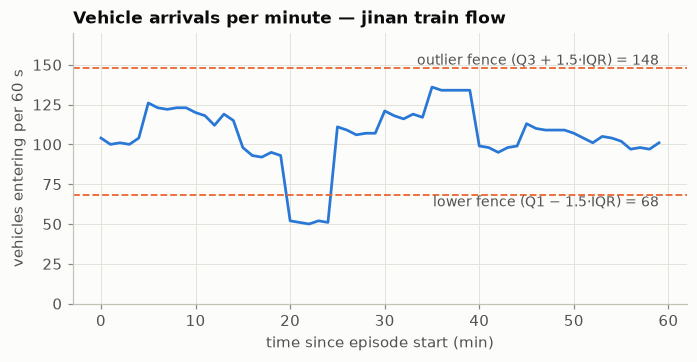

In [6]:
name, split = "jinan", "train"
ds = splits[name]
roadnet = load_roadnet(ds["roadnet"].path)
flows = [v for f in ds["splits"][split] for v in json.loads(f.path.read_text())]
counts = arrival_counts(flows, EPISODE, BIN)
fence, low = burst_threshold(counts), low_threshold(counts)
entry = entry_demand(flows)
moves = movement_demand(flows, roadnet)
lengths = pd.Series([len(v["route"]) for v in flows], name="roads_per_route")
kinds = moves.groupby("kind")["vehicles"].sum()
load = moves.groupby("intersection")["vehicles"].sum()

minutes = np.arange(len(counts)) * BIN / 60
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(minutes, counts, color=BLUE, label="arrivals per minute")
ax.axhline(fence, color=ORANGE, linestyle="--", linewidth=1.2)
ax.axhline(low, color=ORANGE, linestyle="--", linewidth=1.2)
ax.text(minutes[-1], low, f"lower fence (Q1 − 1.5·IQR) = {low:.0f}",
        ha="right", va="top", color=INK_SECONDARY, fontsize=9)
ax.text(minutes[-1], fence, f"outlier fence (Q3 + 1.5·IQR) = {fence:.0f}",
        ha="right", va="bottom", color=INK_SECONDARY, fontsize=9)
ax.set(title=f"Vehicle arrivals per minute — {name} {split} flow",
       xlabel="time since episode start (min)", ylabel=f"vehicles entering per {BIN} s",
       ylim=(0, max(counts.max(), fence) * 1.15))
save_figure(fig, FIG_DIR / f"{name}_{split}_arrivals.png")
plt.show()

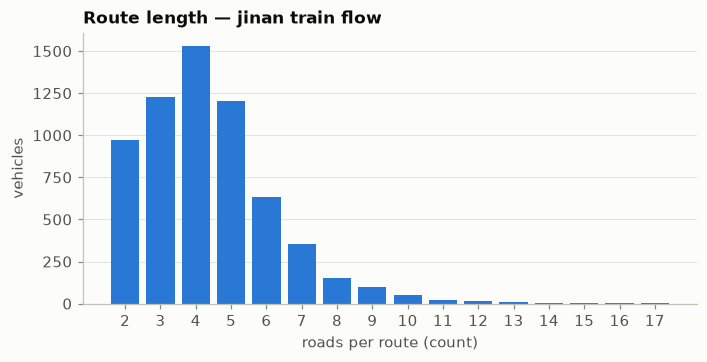

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
vc = lengths.value_counts().sort_index()
ax.bar(vc.index, vc.values, color=BLUE, width=0.8)
ax.set(title=f"Route length — {name} {split} flow", xlabel="roads per route (count)",
       ylabel="vehicles", xticks=range(int(vc.index.min()), int(vc.index.max()) + 1))
ax.grid(axis="x", visible=False)
save_figure(fig, FIG_DIR / f"{name}_{split}_route_length.png")
plt.show()

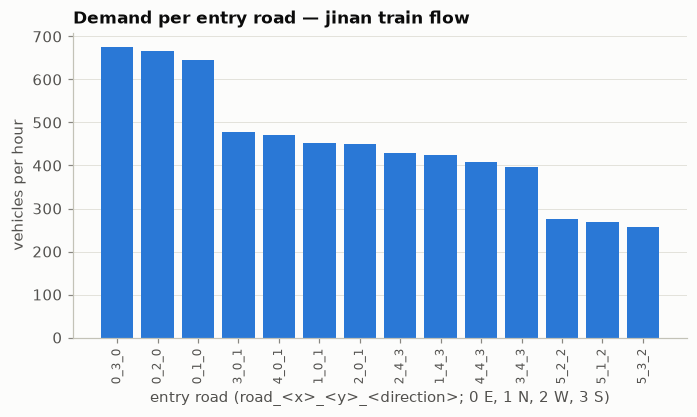

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.bar(range(len(entry)), entry.values, color=BLUE, width=0.8)
ax.set_xticks(range(len(entry)))
ax.set_xticklabels([r.removeprefix("road_") for r in entry.index], rotation=90, fontsize=8)
ax.set(title=f"Demand per entry road — {name} {split} flow",
       xlabel="entry road (road_<x>_<y>_<direction>; 0 E, 1 N, 2 W, 3 S)",
       ylabel="vehicles per hour")
ax.grid(axis="x", visible=False)
save_figure(fig, FIG_DIR / f"{name}_{split}_entry_demand.png")
plt.show()

In [9]:
n_entry_roads = sum(roadnet.road_start[r] in roadnet.virtual_ids for r in roadnet.road_ids)
res["train_description"] = {f"{name}/{split}": {
    "vehicles": len(flows),
    "arrivals_per_bin": {
        "min": int(counts.min()),
        "median": float(np.median(counts)),
        "mean": round(float(counts.mean()), 1),
        "max": int(counts.max()),
        "fence": round(fence, 1),
        "low_fence": round(low, 1),
        "low_bins": int((counts < low).sum()),
        "peak_minute": int(counts.argmax() * BIN // 60),
    },
    "route_roads": {
        "min": int(lengths.min()),
        "median": float(lengths.median()),
        "mean": round(float(lengths.mean()), 2),
        "p95": float(lengths.quantile(0.95)),
        "max": int(lengths.max()),
    },
    "entry_roads_total": n_entry_roads,
    "entry_roads_used": int(len(entry)),
    "entry_top5_share": round(float(entry.head(5).sum() / entry.sum()), 3),
    "entry_max": {"road": entry.index[0], "vehicles": int(entry.iloc[0])},
    "entry_min": {"road": entry.index[-1], "vehicles": int(entry.iloc[-1])},
    "movement_share": {k: round(float(v / kinds.sum()), 3) for k, v in kinds.items()},
    "movements_total": int(len(moves)),
    "movements_unused": int((moves["vehicles"] == 0).sum()),
    "intersection_load": {
        "min": {"id": load.idxmin(), "vehicles": int(load.min())},
        "max": {"id": load.idxmax(), "vehicles": int(load.max())},
    },
}}
(DOCS / "data_audit.json").write_text(json.dumps(res, indent=2) + "\n")
res["train_description"]

{'jinan/train': {'vehicles': 6295,
  'arrivals_per_bin': {'min': 50,
   'median': 106.5,
   'mean': 104.9,
   'max': 136,
   'fence': 148.0,
   'low_fence': 68.0,
   'low_bins': 5,
   'peak_minute': 35},
  'route_roads': {'min': 2,
   'median': 4.0,
   'mean': 4.37,
   'p95': 8.0,
   'max': 17},
  'entry_roads_total': 14,
  'entry_roads_used': 14,
  'entry_top5_share': 0.466,
  'entry_max': {'road': 'road_0_3_0', 'vehicles': 675},
  'entry_min': {'road': 'road_5_3_2', 'vehicles': 257},
  'movement_share': {'go_straight': 0.575,
   'turn_left': 0.144,
   'turn_right': 0.282},
  'movements_total': 144,
  'movements_unused': 0,
  'intersection_load': {'min': {'id': 'intersection_4_3', 'vehicles': 1477},
   'max': {'id': 'intersection_1_1', 'vehicles': 2058}}}}

- No minute is above the upper fence; minutes 20–24 are a low-demand trough (kept, it is real traffic).
- Five entry roads carry a large share of the vehicles; load per intersection is uneven.
- Every movement is used at least once, so no part of the state space is empty in training.